# Mexico GP 2026, FP2: the Verstappen and Lawson penalties in historical context

## Question

On 30 October 2026 the stewards gave Max Verstappen and Liam Lawson a 1-place grid penalty and 1 penalty point each for an
incident in FP2. How does this decision compare with earlier steward decisions on similar incidents, sessions and penalties?

## The decision

From stewards' documents 33 (Verstappen) and 34 (Lawson):

| | |
|---|---|
| **Incident** | A series of moves between Cars 3 and 30 from the entry to Turn 12 to the apex of Turn 14. Car 3 was on a preparation lap and Car 30 on a cool-down lap. |
| **Charge** | FIA International Sporting Code, Appendix L, Chapter IV: Article 2 d) for Verstappen, Article 2 e) for Lawson. Facts and reasoning are otherwise identical. |
| **Penalty** | 1 grid place for the next race and 1 penalty point, for each driver. |
| **Stated reasoning** | Escalated from a formal warning because of a warning at the Team Managers' meeting and "similar incidents this year", and "consistent with other incidents involving contact between the cars in Free Practice in previous years". |

The stewards' own reference to practice contact incidents sets the main comparison group: practice decisions for
*Dangerous Driving* or *Causing a Collision*.

## Approach

Descriptive comparison against every decision in `data/F1Penalties.xlsx`, loaded with the dashboard's own cleaning rules:

1. Filter the full record by successive features of this decision
2. Practice grid penalties other than power-unit changes
3. Outcomes of practice collision and Dangerous Driving decisions (the stewards' stated precedent)
4. Two-car incidents in which both drivers were penalized
5. All decisions with the same penalty, 1 grid place + 1 penalty point
6. Earlier 2026 practice incidents between drivers (the "similar incidents this year" the stewards mention)

Findings and limitations follow at the end.

*Ad hoc local analysis. Not part of the dashboard and not tracked in git.*

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Notebook lives in <project>/adhoc; reuse the dashboard's loader and cleaning rules
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "adhoc" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from data.loader import load_data

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Grey for context, blue for the Mexico decisions or the comparison group being discussed
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, CONTEXT, ACCENT = "#e1e0d9", "#c3c2b7", "#b5b4ad", "#2a78d6"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 24, "figure.dpi": 110,
})


def subtitle(ax, text):
    ax.text(0, 1.01, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")

## Data and definitions

- **Unit of analysis:** one row per driver per steward decision. A two-car incident with a decision for each driver is two rows.
- **Practice:** FP1, FP2 and FP3.
- **Sporting penalty:** any outcome other than no further action, warning, reprimand, fine or overturned. That covers time, grid,
  drive-through, stop-go, disqualification and penalty points.
- **Contact decisions:** allegations categorized as *Dangerous Driving* or *Causing a Collision*. The dataset records both Mexico
  decisions as *Dangerous Driving*, although the stewards cited different articles; the `Article` column below is taken from the
  decision documents.
- **Both penalized:** a decision with a sporting penalty, where a driver named in the incident also received a sporting penalty in
  the same session, in a decision naming this driver.

In [2]:
df = load_data().reset_index(drop=True)

PRACTICE = ["FP1", "FP2", "FP3"]
NON_SPORTING = {"No Further Action", "Warning", "Reprimand", "Fine", "Overturned"}
CONTACT = ["Dangerous Driving", "Causing a Collision"]
FLAGS = ["Yellow Flag Infringement", "Red Flag Infringement"]

df["Short_Year"] = "'" + df["Year"].astype(str).str[-2:]
df["Places"] = pd.to_numeric(df["Grid Penalty"], errors="coerce")
df["Is_Practice"] = df["Session"].isin(PRACTICE)
df["Has_Grid"] = df["Outcome_List"].apply(lambda o: "Grid Penalty" in o)
df["Sporting_Penalty"] = df["Outcome_List"].apply(lambda o: any(x not in NON_SPORTING for x in o))
df["Is_This"] = (
    (df["Year"] == 2026) & (df["Race"] == "Mexico") & (df["Session"] == "FP2")
    & (df["Allegation"] == "Dangerous Driving")
)


def other_driver_also_penalized(row):
    """True when a driver named in this row's incident got a sporting penalty in the same session, and named this driver."""
    if not row["Sporting_Penalty"] or not row["Incident_List"]:
        return False
    same = df[(df["Year"] == row["Year"]) & (df["Round"] == row["Round"]) & (df["Session"] == row["Session"])
              & df["Driver"].isin(row["Incident_List"]) & df["Sporting_Penalty"]]
    return same["Incident_List"].apply(lambda l: row["Driver"] in l).any()


df["Both_Penalized"] = df.apply(other_driver_also_penalized, axis=1)
n_weekends = df[["Year", "Round"]].drop_duplicates().shape[0]

this = df[df["Is_This"]].assign(Article=lambda t: t["Driver"].map(
    {"Max Verstappen": "App. L, Ch. IV, Art. 2 d)", "Liam Lawson": "App. L, Ch. IV, Art. 2 e)"}))

print(f"{len(df):,} decisions over {n_weekends} race weekends, {df['Year'].min()} to Mexico 2026")
print(f"Sessions: {df['Session'].value_counts(dropna=False).to_dict()}\n")
this[["Driver", "Team", "Session", "Allegation", "Article", "Allegation_Raw", "Incident involving",
      "Outcome", "Grid Penalty", "Penalty Points"]]

1,520 decisions over 150 race weekends, 2020 to Mexico 2026
Sessions: {'R': 623, 'Q': 322, 'FP1': 150, 'FP3': 130, 'FP2': 97, 'S': 85, 'SQ': 65, 'Pre-Race': 42, nan: 6}



,Driver,Team,Session,Allegation,Article,Allegation_Raw,Incident involving,Outcome,Grid Penalty,Penalty Points
1518,Max Verstappen,Red Bull,FP2,Dangerous Driving,"App. L, Ch. IV, Art. 2 d)",Series of moves with Car 30 from Turn 12 to Turn 14,Liam Lawson,"Grid Penalty, Penalty Points",1,1
1519,Liam Lawson,RB,FP2,Dangerous Driving,"App. L, Ch. IV, Art. 2 e)",Series of moves with Car 3 from Turn 12 to Turn 14,Max Verstappen,"Grid Penalty, Penalty Points",1,1


## 1. Filtering the record by features of this decision

Each step keeps the decisions that share one more feature of the Mexico decisions. Read this as a description, not as evidence of
how unusual the decision is: the criteria were chosen *after* the event, from its own features, so the funnel will always end
small. Sections 2 to 5 look at each feature against its own comparison group. The x-axis is log scale.

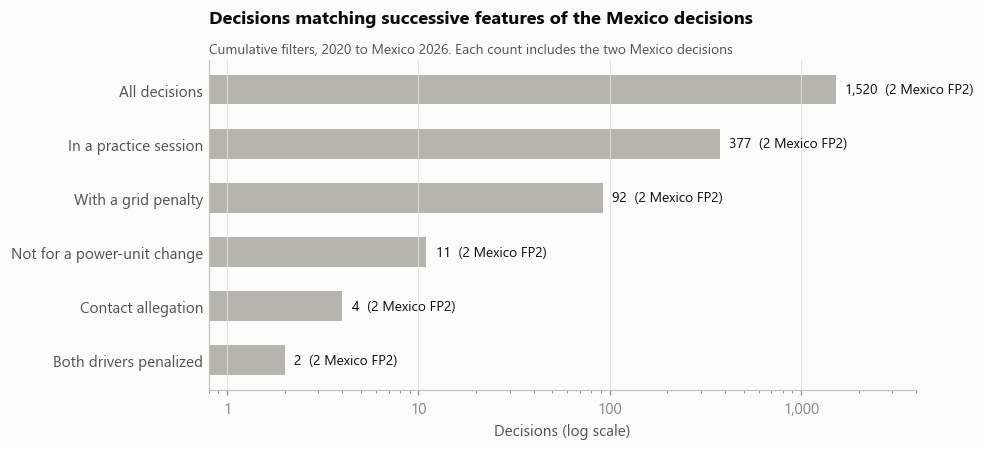

,Step,Decisions,Of which Mexico FP2,% of previous step
0,All decisions,1520,2,NaN
1,In a practice session,377,2,24.8
2,With a grid penalty,92,2,24.4
3,Not for a power-unit change,11,2,12.0
4,Contact allegation,4,2,36.4
5,Both drivers penalized,2,2,50.0


In [3]:
steps = [
    ("All decisions", pd.Series(True, index=df.index)),
    ("In a practice session", df["Is_Practice"]),
    ("With a grid penalty", df["Has_Grid"]),
    ("Not for a power-unit change", df["Allegation"] != "New power unit element(s)"),
    ("Contact allegation", df["Allegation"].isin(CONTACT)),
    ("Both drivers penalized", df["Both_Penalized"]),
]

mask = pd.Series(True, index=df.index)
funnel = []
for label, condition in steps:
    mask &= condition
    funnel.append({"Step": label, "Decisions": int(mask.sum()), "Of which Mexico FP2": int((mask & df["Is_This"]).sum())})
funnel = pd.DataFrame(funnel)
funnel["% of previous step"] = (funnel["Decisions"] / funnel["Decisions"].shift(1) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4.2))
y = list(range(len(funnel)))[::-1]
# Single bars: stacked segments would misstate proportions on a log axis
ax.barh(y, funnel["Decisions"], height=0.55, color=CONTEXT)
ax.set_xscale("log")
ax.set_xlim(0.8, 4000)
ax.set_yticks(y, funnel["Step"])
ax.tick_params(axis="y", length=0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Decisions (log scale)")
ax.grid(axis="y", visible=False)
for yi, v, m in zip(y, funnel["Decisions"], funnel["Of which Mexico FP2"]):
    ax.text(v * 1.12, yi, f"{v:,}  ({m} Mexico FP2)", va="center", fontsize=9)
ax.set_title("Decisions matching successive features of the Mexico decisions")
subtitle(ax, "Cumulative filters, 2020 to Mexico 2026. Each count includes the two Mexico decisions")
plt.tight_layout()
plt.show()

funnel

## 2. Practice grid penalties other than power-unit changes

Most grid penalties given in practice are for power-unit changes, which are technical. This section covers the rest.

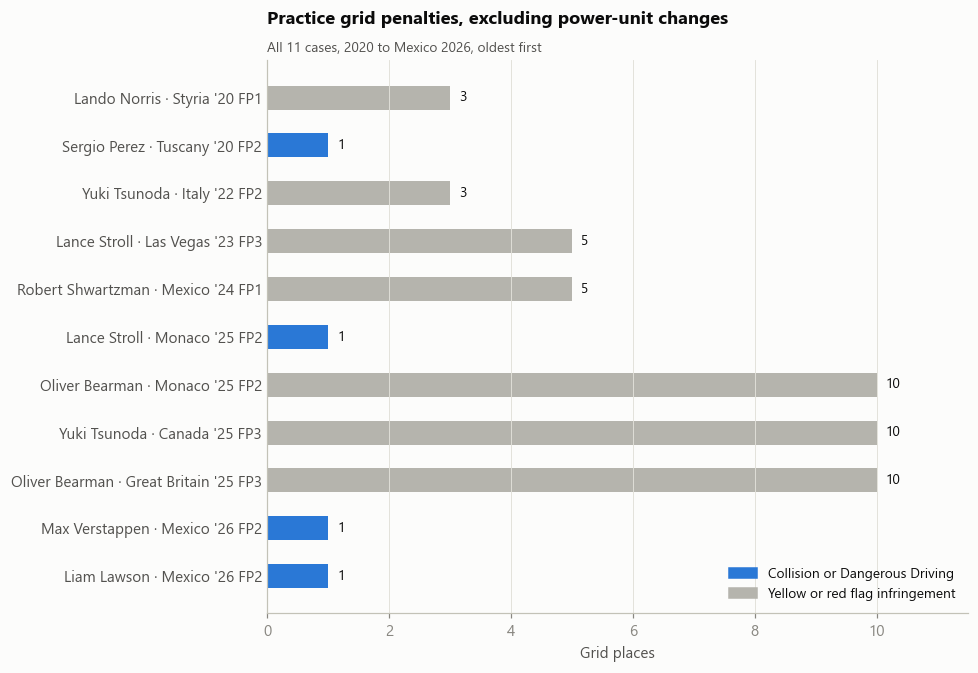

11 cases in 150 race weekends
Grid places by allegation group:


,count,min,max
Group,,,
Contact,4.0,1.0,1.0
Flag,7.0,3.0,10.0


In [4]:
pg = df[df["Is_Practice"] & df["Has_Grid"] & (df["Allegation"] != "New power unit element(s)")].copy()
pg = pg.sort_values(["Year", "Round", "Session"]).reset_index(drop=True)
assert pg["Allegation"].isin(CONTACT + FLAGS).all(), "unexpected allegation category"
pg["Label"] = pg["Driver"] + " · " + pg["Race"] + " " + pg["Short_Year"] + " " + pg["Session"]
is_contact = pg["Allegation"].isin(CONTACT)

fig, ax = plt.subplots(figsize=(9, 0.42 * len(pg) + 1.6))
y = list(range(len(pg)))[::-1]
ax.barh(y, pg["Places"], height=0.5, color=[ACCENT if c else CONTEXT for c in is_contact])
ax.set_yticks(y, pg["Label"])
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, pg["Places"].max() * 1.15)
ax.set_xlabel("Grid places")
for yi, v in zip(y, pg["Places"]):
    ax.text(v + 0.15, yi, f"{v:.0f}", va="center", fontsize=9)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT), plt.Rectangle((0, 0), 1, 1, color=CONTEXT)],
          labels=["Collision or Dangerous Driving", "Yellow or red flag infringement"],
          loc="lower right", frameon=False, fontsize=9)
ax.set_title("Practice grid penalties, excluding power-unit changes")
subtitle(ax, f"All {len(pg)} cases, 2020 to Mexico 2026, oldest first")
plt.tight_layout()
plt.show()

print(f"{len(pg)} cases in {n_weekends} race weekends")
print("Grid places by allegation group:")
pg.assign(Group=is_contact.map({True: "Contact", False: "Flag"})).groupby("Group")["Places"].describe()[["count", "min", "max"]]

## 3. Outcomes of practice contact decisions

This is the comparison group the stewards named. Each decision is placed at its most severe outcome.

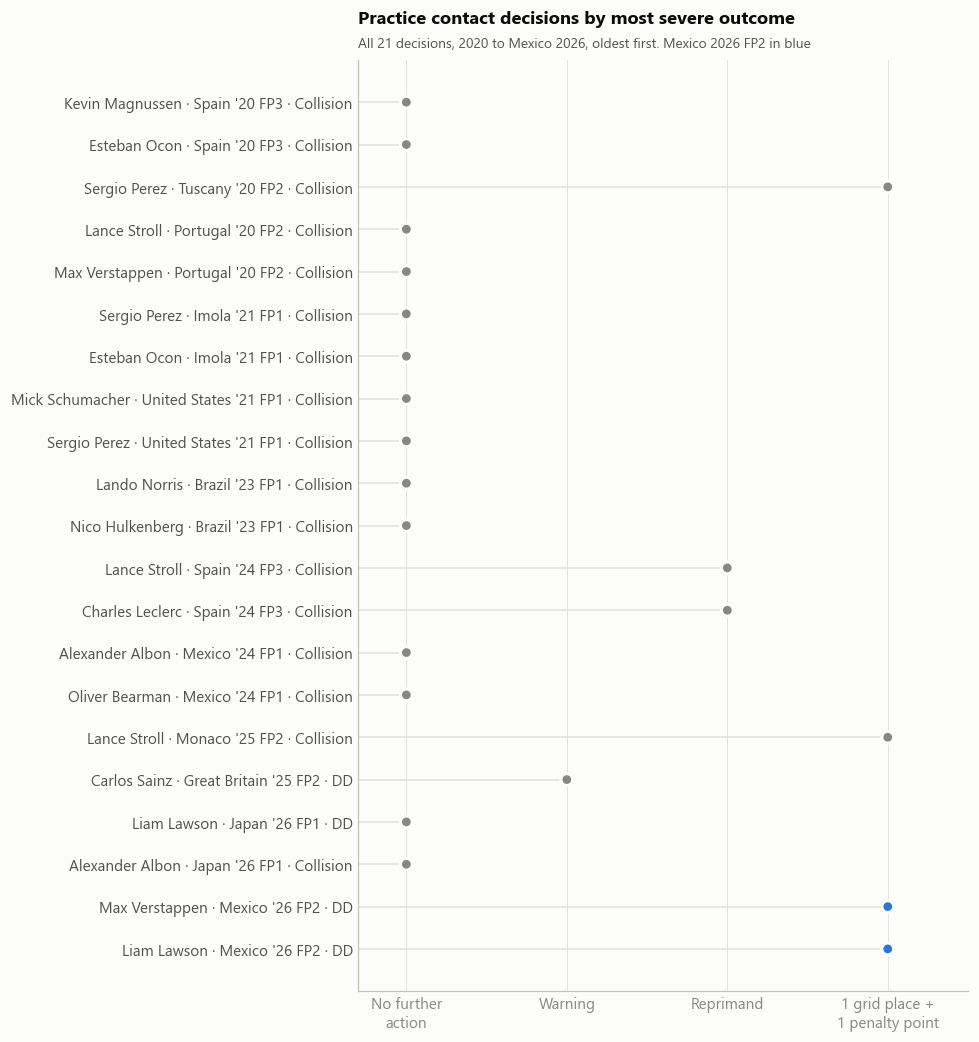

Group,Earlier,Mexico 2026 FP2,Total
Outcome,,,
No Further Action,14,0,14
Warning,1,0,1
Reprimand,2,0,2
"Grid Penalty, Penalty Points",2,2,4


In [5]:
ORDER = ["No Further Action", "Warning", "Reprimand", "Grid Penalty, Penalty Points"]

dd = df[df["Is_Practice"] & df["Allegation"].isin(CONTACT)].copy()
dd = dd.sort_values(["Year", "Round"]).reset_index(drop=True)
assert dd["Outcome"].isin(ORDER).all(), "practice contact outcome outside the expected scale"
dd["Severity"] = dd["Outcome"].map({o: i for i, o in enumerate(ORDER)})
dd["Label"] = (dd["Driver"] + " · " + dd["Race"] + " " + dd["Short_Year"] + " " + dd["Session"]
               + " · " + dd["Allegation"].map({"Dangerous Driving": "DD", "Causing a Collision": "Collision"}))

fig, ax = plt.subplots(figsize=(9, 0.38 * len(dd) + 1.6))
y = list(range(len(dd)))[::-1]
ax.hlines(y, -0.3, dd["Severity"], color=GRID, linewidth=1, zorder=1)
ax.scatter(dd["Severity"], y, s=60, zorder=3, edgecolors=SURFACE, linewidths=2,
           c=[ACCENT if t else MUTED for t in dd["Is_This"]])
ax.set_yticks(y, dd["Label"])
ax.set_xticks(range(len(ORDER)), ["No further\naction", "Warning", "Reprimand", "1 grid place +\n1 penalty point"])
ax.set_xlim(-0.3, len(ORDER) - 0.5)
ax.tick_params(axis="both", length=0)
ax.grid(axis="y", visible=False)
ax.set_title("Practice contact decisions by most severe outcome")
subtitle(ax, f"All {len(dd)} decisions, 2020 to Mexico 2026, oldest first. Mexico 2026 FP2 in blue")
plt.tight_layout()
plt.show()

summary = (dd.assign(Group=dd["Is_This"].map({True: "Mexico 2026 FP2", False: "Earlier"}))
             .pivot_table(index="Outcome", columns="Group", values="Driver", aggfunc="count", fill_value=0)
             .reindex(ORDER))
summary["Total"] = summary.sum(axis=1)
summary

In [6]:
dd[dd["Outcome"] != "No Further Action"][["Year", "Race", "Session", "Driver", "Allegation",
                                          "Incident involving", "Outcome", "Both_Penalized"]]

,Year,Race,Session,Driver,Allegation,Incident involving,Outcome,Both_Penalized
2,2020,Tuscany,FP2,Sergio Perez,Causing a Collision,None,"Grid Penalty, Penalty Points",False
11,2024,Spain,FP3,Lance Stroll,Causing a Collision,Lewis Hamilton,Reprimand,False
12,2024,Spain,FP3,Charles Leclerc,Causing a Collision,Lando Norris,Reprimand,False
15,2025,Monaco,FP2,Lance Stroll,Causing a Collision,Charles Leclerc,"Grid Penalty, Penalty Points",False
16,2025,Great Britain,FP2,Carlos Sainz,Dangerous Driving,Nico Hulkenberg,Warning,False
19,2026,Mexico,FP2,Max Verstappen,Dangerous Driving,Liam Lawson,"Grid Penalty, Penalty Points",True
20,2026,Mexico,FP2,Liam Lawson,Dangerous Driving,Max Verstappen,"Grid Penalty, Penalty Points",True


## 4. Two-car incidents in which both drivers were penalized

This uses incidents investigated for both drivers, meaning each driver has a decision naming the other. Repeated rows for the same
pair and session are merged. All sessions are included.

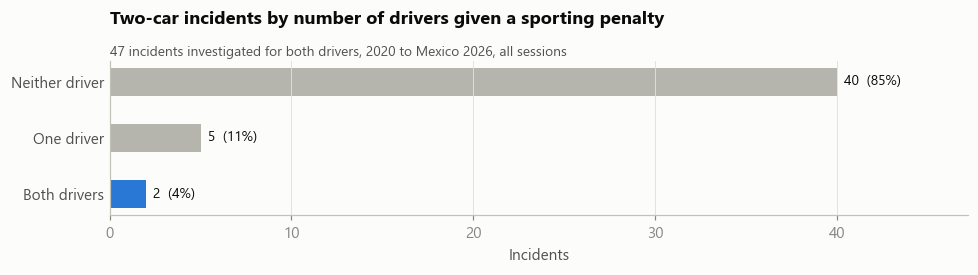

,Year,Race,Session,Drivers,Outcomes
35,2025,Brazil,S,Liam Lawson vs Oliver Bearman,"Liam Lawson: Time Penalty, Penalty Points | Oliver Bearman: Time Penalty, Pe..."
43,2026,Mexico,FP2,Liam Lawson vs Max Verstappen,"Max Verstappen: Grid Penalty, Penalty Points | Liam Lawson: Grid Penalty, Pe..."


In [7]:
linked = df[df["Incident_List"].str.len() > 0]
pairs = {}
for _, a in linked.iterrows():
    for other in a["Incident_List"]:
        b = linked[(linked["Year"] == a["Year"]) & (linked["Round"] == a["Round"])
                   & (linked["Session"] == a["Session"]) & (linked["Driver"] == other)
                   & linked["Incident_List"].apply(lambda l: a["Driver"] in l)]
        for _, b_row in b.iterrows():
            key = (a["Year"], a["Round"], a["Session"], frozenset([a["Driver"], other]))
            pairs.setdefault(key, {
                "Year": a["Year"], "Race": a["Race"], "Session": a["Session"],
                "Drivers": " vs ".join(sorted([a["Driver"], other])),
                "Penalized": int(a["Sporting_Penalty"]) + int(b_row["Sporting_Penalty"]),
                "Outcomes": f"{a['Driver']}: {a['Outcome']} | {other}: {b_row['Outcome']}",
            })
pairs = pd.DataFrame(pairs.values()).sort_values(["Year", "Race"]).reset_index(drop=True)

buckets = pairs["Penalized"].value_counts().reindex([0, 1, 2], fill_value=0)
buckets.index = ["Neither driver", "One driver", "Both drivers"]

fig, ax = plt.subplots(figsize=(9, 2.6))
y = list(range(len(buckets)))[::-1]
ax.barh(y, buckets.values, height=0.5, color=[CONTEXT, CONTEXT, ACCENT])
ax.set_yticks(y, buckets.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, buckets.max() * 1.18)
ax.set_xlabel("Incidents")
for yi, v in zip(y, buckets.values):
    ax.text(v + 0.4, yi, f"{v}  ({v / len(pairs):.0%})", va="center", fontsize=9)
ax.set_title("Two-car incidents by number of drivers given a sporting penalty")
subtitle(ax, f"{len(pairs)} incidents investigated for both drivers, 2020 to Mexico 2026, all sessions")
plt.tight_layout()
plt.show()

pairs[pairs["Penalized"] == 2][["Year", "Race", "Session", "Drivers", "Outcomes"]]

## 5. Decisions with the same penalty: 1 grid place + 1 penalty point

Five decisions in the record have exactly this penalty. Four are practice contact decisions from section 3. The fifth is
Verstappen's Qatar 2024 qualifying decision for *Driving Unnecessarily Slowly*, involving George Russell. It was charged as slow
driving rather than impeding because both cars were on slow laps, so the like-for-like comparison is other slow-driving decisions,
summarized below the chart.

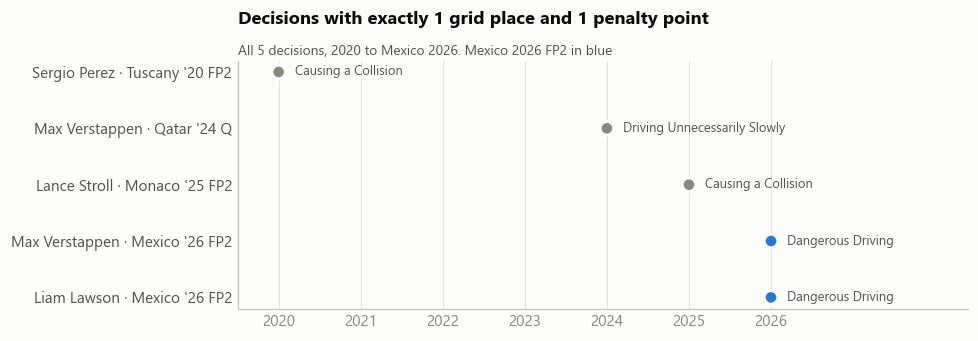

Driving Unnecessarily Slowly: 39 decisions in all sessions, 1 with a grid penalty
In Q/SQ: 18 decisions, outcomes {'No Further Action': 10, 'Warning': 4, 'Reprimand': 3, 'Grid Penalty, Penalty Points': 1}
Q/SQ slow-driving decisions naming another driver: 1 (Qatar 2024)

2026 grid penalties other than power-unit and parc fermé: 11, by session {'Q': 7, 'FP2': 2, 'SQ': 1, 'R': 1}


,Year,Race,Session,Driver,Allegation,Incident involving
0,2020,Tuscany,FP2,Sergio Perez,Causing a Collision,None
1,2024,Qatar,Q,Max Verstappen,Driving Unnecessarily Slowly,George Russell
2,2025,Monaco,FP2,Lance Stroll,Causing a Collision,Charles Leclerc
3,2026,Mexico,FP2,Max Verstappen,Dangerous Driving,Liam Lawson
4,2026,Mexico,FP2,Liam Lawson,Dangerous Driving,Max Verstappen


In [8]:
one_one = df[(df["Places"] == 1) & (df["Penalty Points"] == 1)].sort_values(["Year", "Round"]).reset_index(drop=True)
one_one["Label"] = one_one["Driver"] + " · " + one_one["Race"] + " " + one_one["Short_Year"] + " " + one_one["Session"]

fig, ax = plt.subplots(figsize=(9, 3.2))
y = list(range(len(one_one)))[::-1]
ax.scatter(one_one["Year"], y, s=80, zorder=3, edgecolors=SURFACE, linewidths=2,
           c=[ACCENT if t else MUTED for t in one_one["Is_This"]])
ax.set_yticks(y, one_one["Label"])
ax.set_xticks(range(df["Year"].min(), df["Year"].max() + 1))
ax.set_xlim(df["Year"].min() - 0.5, df["Year"].max() + 2.4)
ax.tick_params(axis="both", length=0)
ax.grid(axis="y", visible=False)
for yi, (_, row) in zip(y, one_one.iterrows()):
    ax.text(row["Year"] + 0.2, yi, row["Allegation"], va="center", fontsize=8.5, color=INK_2)
ax.set_title("Decisions with exactly 1 grid place and 1 penalty point")
subtitle(ax, f"All {len(one_one)} decisions, 2020 to Mexico 2026. Mexico 2026 FP2 in blue")
plt.tight_layout()
plt.show()

slow = df[df["Allegation"] == "Driving Unnecessarily Slowly"]
slow_q = slow[slow["Session"].isin(["Q", "SQ"])]
print(f"Driving Unnecessarily Slowly: {len(slow)} decisions in all sessions, {slow['Has_Grid'].sum()} with a grid penalty")
print(f"In Q/SQ: {len(slow_q)} decisions, outcomes {slow_q['Outcome'].value_counts().to_dict()}")
print(f"Q/SQ slow-driving decisions naming another driver: {(slow_q['Incident_List'].str.len() > 0).sum()} (Qatar 2024)")

y26 = df[(df["Year"] == 2026) & df["Has_Grid"] & (df["Allegation"] != "New power unit element(s)")
         & (df["Allegation"] != "Changes made under Parc Ferme")]
print(f"\n2026 grid penalties other than power-unit and parc fermé: {len(y26)}, by session "
      f"{y26['Session'].value_counts().to_dict()}")
one_one[["Year", "Race", "Session", "Driver", "Allegation", "Incident involving"]]

## 6. Earlier 2026 practice incidents between drivers

The stewards cite "similar incidents this year of actions between drivers in Free Practice" but don't say which. This section lists
the candidates: 2026 practice decisions before Mexico for on-track conduct towards another car. Those are Dangerous Driving,
Causing a Collision, Impeding, Driving Erratically, Forcing Another Car Off Track, Leaving the Track and Rejoining Unsafely, and
Driving Unnecessarily Slowly. Pit-lane and flag cases are left out. Where this boundary sits is a judgement call.

It also records whether Verstappen or Lawson was the driver investigated, or was named as the other driver.

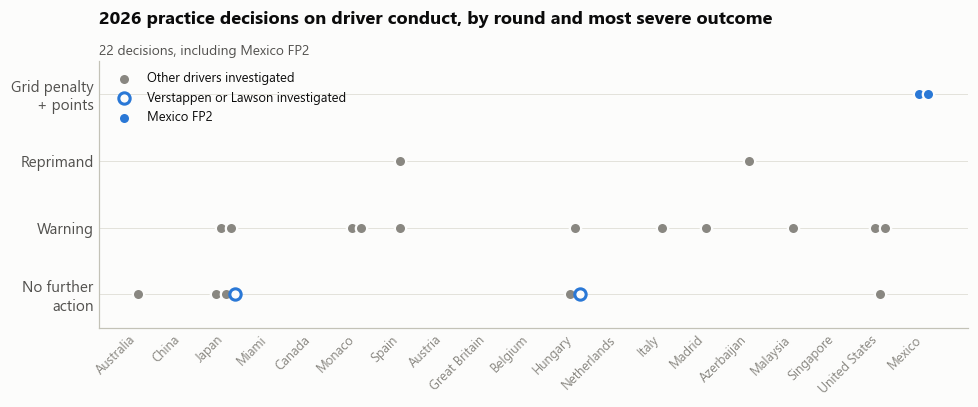

Before Mexico: 20 decisions. Most severe outcomes: {'Warning': 11, 'No further action': 7, 'Reprimand': 2}
Sporting penalties before Mexico: 0
Verstappen/Lawson investigated: 2, named as the other driver: 5, against each other: 0


,Race,Session,Driver,Allegation,Incident involving,Outcome,Role
2,Japan,FP1,Lewis Hamilton,Impeding,Max Verstappen,No Further Action,Other driver
3,Japan,FP1,Liam Lawson,Dangerous Driving,Carlos Sainz,No Further Action,Investigated
4,Japan,FP2,Franco Colapinto,Impeding,Max Verstappen,Warning,Other driver
7,Monaco,FP1,Charles Leclerc,Impeding,Liam Lawson,Warning,Other driver
11,Hungary,FP1,Carlos Sainz,Impeding,Max Verstappen,Warning,Other driver
12,Hungary,FP1,Max Verstappen,Driving Erratically,None,No Further Action,Investigated
15,Azerbaijan,FP2,Lewis Hamilton,Impeding,Liam Lawson,Reprimand,Other driver


In [9]:
CONDUCT = CONTACT + ["Impeding", "Driving Erratically", "Forcing Another Car Off Track",
                     "Leaving the Track and Rejoining Unsafely", "Driving Unnecessarily Slowly"]
PAIR = ["Max Verstappen", "Liam Lawson"]
SEV = {"No Further Action": 0, "Warning": 1, "Fine": 1, "Reprimand": 2, "Grid Penalty": 3, "Penalty Points": 3}
SEV_LABELS = ["No further\naction", "Warning", "Reprimand", "Grid penalty\n+ points"]

p26 = df[(df["Year"] == 2026) & df["Is_Practice"] & df["Allegation"].isin(CONDUCT)].copy()
assert p26["Outcome_List"].apply(lambda o: all(x in SEV for x in o)).all(), "outcome outside the expected scale"
p26["Severity"] = p26["Outcome_List"].apply(lambda o: max(SEV[x] for x in o))
p26["Role"] = p26.apply(lambda r: "Investigated" if r["Driver"] in PAIR
                        else ("Other driver" if set(PAIR) & set(r["Incident_List"]) else ""), axis=1)
p26 = p26.sort_values(["Round", "Session", "Driver"]).reset_index(drop=True)

# Spread decisions that share a round and outcome so every dot is visible
grp = p26.groupby(["Round", "Severity"])
p26["X"] = p26["Round"].astype(float) + (grp.cumcount() - (grp["Driver"].transform("size") - 1) / 2) * 0.22

pair_investigated = p26["Role"].eq("Investigated") & ~p26["Is_This"]
fig, ax = plt.subplots(figsize=(9, 3.8))
other = ~p26["Is_This"] & ~pair_investigated
ax.scatter(p26.loc[other, "X"], p26.loc[other, "Severity"], s=55, color=MUTED, edgecolors=SURFACE, linewidths=1.5,
           zorder=3, label="Other drivers investigated")
ax.scatter(p26.loc[pair_investigated, "X"], p26.loc[pair_investigated, "Severity"], s=55, facecolors=SURFACE,
           edgecolors=ACCENT, linewidths=2, zorder=3, label="Verstappen or Lawson investigated")
ax.scatter(p26.loc[p26["Is_This"], "X"], p26.loc[p26["Is_This"], "Severity"], s=55, color=ACCENT,
           edgecolors=SURFACE, linewidths=1.5, zorder=3, label="Mexico FP2")
rounds = df[df["Year"] == 2026][["Round", "Race"]].drop_duplicates().set_index("Round")["Race"].str.rstrip("*")
ax.set_xticks(rounds.index, rounds.values, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(len(SEV_LABELS)), SEV_LABELS)
ax.set_ylim(-0.5, len(SEV_LABELS) - 0.5)
ax.tick_params(axis="both", length=0)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.set_title("2026 practice decisions on driver conduct, by round and most severe outcome")
subtitle(ax, f"{len(p26)} decisions, including Mexico FP2")
plt.tight_layout()
plt.show()

before = p26[~p26["Is_This"]]
print(f"Before Mexico: {len(before)} decisions. Most severe outcomes: "
      f"{before['Severity'].map(dict(enumerate(['No further action', 'Warning', 'Reprimand', 'Grid penalty']))).value_counts().to_dict()}")
print(f"Sporting penalties before Mexico: {before['Sporting_Penalty'].sum()}")
print(f"Verstappen/Lawson investigated: {before['Role'].eq('Investigated').sum()}, "
      f"named as the other driver: {before['Role'].eq('Other driver').sum()}, "
      f"against each other: {before.apply(lambda r: r['Driver'] in PAIR and set(PAIR) - {r['Driver']} <= set(r['Incident_List']), axis=1).sum()}")
before[before["Role"] != ""][["Race", "Session", "Driver", "Allegation", "Incident involving", "Outcome", "Role"]]

In [10]:
# The most recent comparable case: preparation-lap conduct one round before Mexico
prev_round = p26.loc[p26["Is_This"], "Round"].iat[0] - 1
before[before["Round"] == prev_round][["Race", "Session", "Driver", "Allegation", "Allegation_Raw",
                                       "Incident involving", "Outcome", "Notes"]]

,Race,Session,Driver,Allegation,Allegation_Raw,Incident involving,Outcome,Notes
17,United States,FP2,George Russell,Forcing Another Car Off Track,NaN,Charles Leclerc,No Further Action,Both cars on preparation laps
18,United States,FP3,Gabriel Bortoleto,Impeding,NaN,Lewis Hamilton,Warning,NaN
19,United States,FP3,Isack Hadjar,Driving Erratically,Swerved towards another car after aborting a lap,Alexander Albon,Warning,NaN


## Findings

The figures below are computed from the cells above.

In [11]:
prior_contact = dd[~dd["Is_This"]]
both = pairs[pairs["Penalized"] == 2]
other_both = both[both["Race"] != "Mexico"].iloc[0]
contact_grid = dd[dd["Has_Grid"]]
flag_places = pg.loc[~pg["Allegation"].isin(CONTACT), "Places"]
y26_practice = y26[y26["Session"].isin(PRACTICE)]

print(f"""1. Penalty size. All {len(contact_grid)} grid penalties for practice contact have been 1 place + 1 point:
   {', '.join(f"{r.Driver} ({r.Race} {r.Year})" for r in contact_grid.itertuples())}.
   Mexico matches the earlier precedent the stewards cited. Practice flag infringements drew {flag_places.min():.0f}–{flag_places.max():.0f} places.

2. Penalty frequency. {len(contact_grid)} of {len(dd)} practice contact decisions ended in a grid penalty.
   Of the {len(prior_contact)} earlier decisions: {prior_contact['Outcome'].value_counts().to_dict()}.

3. Both drivers penalized. {len(both)} of {len(pairs)} two-sided incidents ({len(both) / len(pairs):.0%}), all sessions:
   {other_both['Drivers']} ({other_both['Race']} {other_both['Year']}, {other_both['Session']}) and Mexico 2026 FP2.
   Mexico is the only practice incident in the record where both drivers were penalized.

4. Context for 2026. Of {len(y26)} grid penalties in 2026 other than power-unit and parc fermé, {len(y26_practice)} came from
   practice ({', '.join(y26_practice['Driver'])}, {y26_practice['Race'].iat[0]}). The rest came from qualifying, sprint
   qualifying or a race.

5. Charging. The two decisions cite different articles (2 d and 2 e) for the same facts and give the same penalty.

6. Earlier 2026 practice incidents. {len(before)} conduct decisions before Mexico, {before['Sporting_Penalty'].sum()} with a sporting penalty.
   Verstappen and Lawson were each investigated once ({', '.join(f"{r.Driver.split()[-1]} {r.Race} {r.Session}: {r.Outcome}" for r in before[before['Role'] == 'Investigated'].itertuples())})
   and named as the other driver {before['Role'].eq('Other driver').sum()} times. None of these decisions was between the two of them.
""")

1. Penalty size. All 4 grid penalties for practice contact have been 1 place + 1 point:
   Sergio Perez (Tuscany 2020), Lance Stroll (Monaco 2025), Max Verstappen (Mexico 2026), Liam Lawson (Mexico 2026).
   Mexico matches the earlier precedent the stewards cited. Practice flag infringements drew 3–10 places.

2. Penalty frequency. 4 of 21 practice contact decisions ended in a grid penalty.
   Of the 19 earlier decisions: {'No Further Action': 14, 'Grid Penalty, Penalty Points': 2, 'Reprimand': 2, 'Warning': 1}.

3. Both drivers penalized. 2 of 47 two-sided incidents (4%), all sessions:
   Liam Lawson vs Oliver Bearman (Brazil 2025, S) and Mexico 2026 FP2.
   Mexico is the only practice incident in the record where both drivers were penalized.

4. Context for 2026. Of 11 grid penalties in 2026 other than power-unit and parc fermé, 2 came from
   practice (Max Verstappen, Liam Lawson, Mexico). The rest came from qualifying, sprint
   qualifying or a race.

5. Charging. The two decisions

## Interpretation

The *size* of the penalty is consistent with precedent. Every earlier grid penalty for practice contact was also 1 place + 1
point, which supports the stewards' statement that the decision was consistent with previous years.

What is unusual is the *combination*: a sporting penalty, rather than a warning or no action, for practice contact, given to both
drivers. The stewards explain this as an escalation following an explicit warning that day. Earlier 2026 practice conduct
cases ended in warnings, reprimands or no action, including a preparation-lap case one round earlier, which fits that account.
The data can't confirm which earlier incidents the stewards had in mind. Neither driver was penalized in any of them. The data can show that this
combination has no precedent in the record. It cannot show whether the escalation was justified.

## Limitations

- **Coverage:** 2020 to Mexico 2026 only. "No precedent" means within this record, not all of Formula 1 history.
- **Post hoc criteria:** the comparison groups were defined from features of this event. Under enough conditioning any event
  looks unique, so the funnel in section 1 is descriptive only.
- **Small numbers:** the comparison groups have 21 and 47 members, and each count is driven by a few cases. Percentages describe
  the record; they are not estimates of how stewards rule.
- **Two-sided incidents:** these are identified only when each driver's decision names the other, so incidents investigated for
  one driver only are missed and 47 is a minimum.
- **Classification:** allegations are grouped into standard categories. Both Mexico decisions are coded *Dangerous Driving* despite
  different articles, and grouping Dangerous Driving with Causing a Collision is a judgement call that follows the stewards' own
  reference to contact incidents.
- **Context not in the data:** severity, intent, contact versus no contact, and the warning at the Team Managers' meeting are only
  available as free text in the decision documents, so they are not modelled here.
- **Known data issue:** Albon's Miami 2026 Sprint Qualifying decision is coded as a grid penalty but was a lap-time deletion. It
  does not affect the practice results here.